In [13]:
from functools import partial
from pathlib import Path
from typing import Any, Callable, Iterable, Optional

import numpy as np
from numpy.typing import NDArray
import matplotlib as mpl
import matplotlib.pyplot as plt
import pandas as pd

from bloodmoon.mask import CodedMaskCamera, codedmask
from bloodmoon.mask import count, decode, variance
from bloodmoon.io import simulation_files
from bloodmoon.images import argmax
from bloodmoon.optim import model_shadowgram
from bloodmoon.types import CoordEquatorial
import darksun as ds
from darksun.data import Log, DataLoader, CatalogueLoader

from IROSrec.iros.procedure import iros_singleCAM, run_IROS, get_sources_database
from IROSrec.handle import config_dirpaths
import imgmaker as mgm

plt.rcdefaults()
RCPARAMS = {
    'axes.formatter.limits': (-3, 3),
    'savefig.bbox': 'tight',
}
mpl.rcParams.update(RCPARAMS)

In [14]:
def find_boxmax(sky: NDArray, centre: tuple[int, int], boxsize: int = 5) -> tuple[int, int]:
    """Finds the argmax of given sky in a box centered around `pos`."""
    rcut, ccut = map(lambda idx: slice(idx - boxsize, idx + boxsize + 1), centre)
    p, q = centre
    n, m = argmax(sky[rcut, ccut])
    return p - boxsize + n, q - boxsize + m

def comp_src_mstd(log: Log, varmap: NDArray, boxsize: tuple[int, int]) -> NDArray:
    """Computes the RMSE for each IROS source from given varmap in specified array box."""
    mstds: list[float] = []
    boxsize_ = (max(boxsize[0], 1), max(boxsize[1], 1))
    for y, x in zip(log.log['y'], log.log['x']):
        srows, scols = (
            slice(y - boxsize_[0], y + boxsize_[0] + 1),
            slice(x - boxsize_[1], x + boxsize_[1] + 1),
        )
        mstd = np.sqrt(np.mean(varmap[srows, scols]))
        mstds.append(mstd)
    return np.array(mstds)

def gather_cam_data(
    log: Log,
    catalogue: CatalogueLoader,
    sdl: DataLoader,
    camera: CodedMaskCamera,
    varmap: NDArray,
) -> pd.DataFrame:
    """
    Gathers single camera data from IROS reconstruction database.
    """
    ids = np.array([src.upper() for src in log.log['ID']])
    theta_res_x, theta_res_y = mgm.get_angularcoords_residues(log, catalogue, sdl, camera)
    cts = np.array(log.log['fluence']).round(decimals=0)
    true_cts = mgm.extract_catalogue_fluences(log, catalogue, sdl, camera)
    src_mstd = comp_src_mstd(log, varmap, boxsize=tuple(int(np.ceil(a // 2)) for a in ds.psf_extension(camera)[::-1]))
    dmap = {
        'Source': ids,
        'DthetaX': theta_res_x,
        'DthetaY': theta_res_y,
        'True_cts': true_cts,
        'IROS_cts': cts,
        'Dcts': (cts - true_cts) / src_mstd,
        'SNR': np.array(log.log['snr']),
    }
    return pd.DataFrame(dmap)

In [15]:
MASK_FITS: str = "mask_NTHT_20250725.fits"
SKYFIELD: str = "GalacticCentre"
DATA_FITS: str = "galctr_rxte-sax_mask_050_1040x17_2-50keV_1ks_mask25"

ID_CAMERA_A: str = "cam1a"
ID_CAMERA_B: str = "cam1b"
DATASET: str = "reconstructed"

E_min: float = 2.0  # [keV]
E_max: float = 50.0  # [keV]

UPS_X, UPS_Y = 5, 1
hide_bulk_els_y: float = 1.5   # [mm]

VIGNETTING: bool = True
PSFY: bool = mgm.config_psfy_flag(DATASET)

In [16]:
MASK_PATH, SIMUL_DATA_PATH, SAVE_PATH = config_dirpaths(
    mask=MASK_FITS,
    skyfield=SKYFIELD,
    simul=DATA_FITS,
)

wfm: CodedMaskCamera = codedmask(MASK_PATH, UPS_X, UPS_Y, hide_bulk_els_y=hide_bulk_els_y)

filepaths: dict[str, dict[str, Path]] = simulation_files(SIMUL_DATA_PATH)
catA = ds.get_catalogue(filepaths[ID_CAMERA_A]['sources'])
catB = ds.get_catalogue(filepaths[ID_CAMERA_B]['sources'])

In [17]:
retain_src = ['scox1', '-1', 'gctr_diffuse']

_, unique_idxs = np.unique(catA.DLdata['ID'], return_index=True)
cat_coords = catA.DLdata[unique_idxs]

coords2exclude: list[CoordEquatorial] | None = [
    CoordEquatorial(ra, dec) for srcID, ra, dec in zip(cat_coords['ID'], cat_coords['RA'], cat_coords['DEC'])
    if srcID not in retain_src
]

# assert len(retain_src) + len(coords2exclude) == len(cat_coords), f'{len(retain_src)} + {len(coords2exclude)} != {len(cat_coords)}'
print(f'Excluded {len(coords2exclude)} / {len(cat_coords)} sources from data')

sdlA, sdlB = map(
    lambda camID: ds.get_data(filepaths[camID][DATASET], E_min=E_min, E_max=E_max, coords=coords2exclude),
    (ID_CAMERA_A, ID_CAMERA_B),
)
sddA, sddB = map(lambda sdl: count(wfm, sdl.DLdata)[0], (sdlA, sdlB))
skymapA, skymapB = map(lambda sdd: decode(wfm, sdd), (sddA, sddB))
varmapA, varmapB = map(lambda sdd: variance(wfm, sdd), (sddA, sddB))

Excluded 170 / 173 sources from data
UserInfo: using bulk mask of [0.0 x 1.5] mm.


In [18]:
def comp_fit_weights(obs: NDArray) -> NDArray:
    """Computes the weights for the loss metric in the optimisation procedure."""
    return 1.0 / np.sqrt(np.clip(obs, a_min=1.0, a_max=None))

get_loop: Callable[[], Iterable] = partial(
    iros_singleCAM,
    camera=wfm,
    max_iterations=1,
    snr_threshold=5.0,
    vignetting=VIGNETTING,
    psfy=PSFY,
    fit_weights=comp_fit_weights,
)

In [19]:
loop = get_loop(detector=sddA, varmap=varmapA)
log_camA, skyA = run_IROS(wfm, loop, ID_CAMERA_A)
loop = get_loop(detector=sddB, varmap=varmapB)
log_camB, skyB = run_IROS(wfm, loop, ID_CAMERA_B)

log_camA, log_camB = (
    get_sources_database(wfm, sdlA, catA, log_camA, VIGNETTING),
    get_sources_database(wfm, sdlB, catB, log_camB, VIGNETTING),
)

# Looping around the FOV...


IROS sky-reconstruction: 0it [00:00, ?it/s]


## Optimisation Results:
  * p[0]:
      - START.: 43.9000000
      - OPTIM.: 43.9148401 +/- 0.0000106
      - GAIN.: 0.034 %
  * p[1]:
      - START.: 78.0000000
      - OPTIM.: 78.0618283 +/- 0.0005838
      - GAIN.: 0.079 %
  * p[2]:
      - START.: 1105062.5086372
      - OPTIM.: 1021468.1462981 +/- 57.1650163
      - GAIN.: -7.565 %

## Fit Report:
  - func calls (also # of iters): 6
  - procedure msg: Both `ftol` and `xtol` termination conditions are satisfied.
  - success status 4: Convergence in orthogonality



IROS sky-reconstruction: 1it [00:19, 19.58s/it]


# Looping around the FOV...


IROS sky-reconstruction: 0it [00:00, ?it/s]


## Optimisation Results:
  * p[0]:
      - START.: 78.0500000
      - OPTIM.: 78.0558459 +/- 0.0000466
      - GAIN.: 0.007 %
  * p[1]:
      - START.: -44.0000000
      - OPTIM.: -43.9146253 +/- 0.0021481
      - GAIN.: 0.194 %
  * p[2]:
      - START.: 956602.7397316
      - OPTIM.: 885891.8016851 +/- 190.0064370
      - GAIN.: -7.392 %

## Fit Report:
  - func calls (also # of iters): 6
  - procedure msg: `ftol` termination condition is satisfied.
  - success status 2: Convergence in parameter values



IROS sky-reconstruction: 1it [00:18, 18.94s/it]


# Comparing with Catalogue...
# Successful comparison!
# Comparing with Catalogue...
# Successful comparison!


In [20]:
ds.pixels_angular_resolution(wfm)
# Table - CAMERA A
data_camA = gather_cam_data(log_camA, catA, sdlA, wfm, varmapA)
# Table - CAMERA B
data_camB = gather_cam_data(log_camB, catB, sdlB, wfm, varmapB)

data_camA, data_camB


Pixel angular resolution at upscaling (x, y): (5, 1)
  - fine direction: 0.8465 arcmin
  - coarse direction: 8.4653 arcmin



Analysing SCOX1: 100%|██████████| 1/1 [00:00<00:00,  1.63it/s]


(  Source   DthetaX   DthetaY   True_cts   IROS_cts       Dcts         SNR
 0  SCOX1  0.087947  0.236231  1053180.0  1021468.0 -29.953689  886.635267,
   Source   DthetaX   DthetaY  True_cts  IROS_cts       Dcts         SNR
 0  SCOX1  0.147988 -0.084474  941404.0  885892.0 -56.065081  823.602387)

In [21]:
def find_tick_val(ticks: NDArray, trg_vals: NDArray, atol: float = 1e-4) -> NDArray:
    """Finds the idxs inside `ticks` relative to given values `trg_vals`."""
    trg_idxs: list[int] = []
    for v in trg_vals:
        idx = np.argwhere(np.isclose(ticks, v, atol=atol))
        if idx.size > 0: trg_idxs.append(idx[0, 0])
    return np.array(trg_idxs)

def set_phase(x: NDArray) -> NDArray:
    """Centers `x` values around zero."""
    return np.arange(len(x) + 1) - len(x) // 2 - 0.5

def get_slices(*arrs: NDArray) -> tuple[tuple[NDArray, ...], tuple[NDArray, ...]]:
    n, m = arrs[0].shape
    xslice, yslice = zip(*tuple((c[(n - 1) // 2, :], c[:, (m - 1) // 2]) for c in arrs))
    return xslice, yslice

def get_heatmap_plot_data(
    psf: NDArray,
    psf_err: NDArray,
    modelled: NDArray,
    modelled_err: NDArray,
    mode: str,
    express_res_perc: bool,
) -> tuple[NDArray, str]:
    """Handles source PSF residuals heatmap to plot."""
    if mode == 'ratio':
        return psf / modelled, 'ratio'

    res = psf - modelled
    if mode == 'res':
        lbl = 'residuals [ph]'
        if express_res_perc:
            res = res * 100 / psf.max()
            lbl = r'residuals [%]'
        return res, lbl

    sigma = np.sqrt(np.square(psf_err) + np.square(modelled_err))
    return res / sigma, 'residuals [$\\sigma$]'

def get_slices_plot_data(
    psf: NDArray,
    psf_err: NDArray,
    modelled: NDArray,
    modelled_err: NDArray,
    mode: str,
    express_res_perc: bool,
    n_sigma: int,
) -> tuple[NDArray, NDArray, str]:
    """
    Handles data to plot from source PSF and sigma slices, for both true and modelled.
    """
    if mode not in ('res', 'ratio', 'sigma'):
        raise ValueError(f"Invalid input mode '{mode}'.")
    
    if mode == 'ratio':
        sigma = psf_err / np.abs(modelled) + np.abs(psf / np.square(modelled)) * modelled_err
        return psf / modelled, n_sigma * sigma, 'ratio'

    res = psf - modelled
    sigma = np.sqrt(np.square(psf_err) + np.square(modelled_err))

    if mode == 'res':
        lbl = 'residuals [counts]'
        if express_res_perc:
            res, sigma = map(lambda x: x * 100 / psf.max(), (res, sigma))
            lbl = r'residuals [%]'
        return res, n_sigma * sigma, lbl

    return res / sigma, n_sigma * np.ones_like(res), 'residuals [$\\sigma$]'

def show_PSF_total(
    camera: CodedMaskCamera,
    true_w_err: tuple[NDArray, NDArray],
    modelled_w_err: tuple[NDArray, NDArray],
    save_to: str | None = None,
    express_res_perc: bool = True,
    express_res_sigma: bool = False,
    n_sigma: int = 1,
    cts_lims: tuple = (None, None),
    hm_ratio_lims: tuple = (None, None),
    fine_ratio_lims: tuple = (None, None),
    coarse_ratio_lims: tuple = (None, None),
    save_options: dict[str, Any] | None = None,
    **fig_kws,
) -> None:
    """
    Plots the source PSF heat maps and profiles along fine/coarse axes + cfr with modelled source.
    """
    res_mode = 'res'
    if express_res_sigma:
        express_res_perc = False
        res_mode = 'sigma'

    title_fs = 16
    lbl_fs = 14
    
    dtx, dty = ds.pixels_angular_resolution(camera, verbose=False)
    psf, modelled = true_w_err[0], modelled_w_err[0]
    psf_xslice, psf_yslice = get_slices(*true_w_err)
    modelled_xslice, modelled_yslice = get_slices(*modelled_w_err)

    phase_fine, phase_coarse = (
        dtx * set_phase(psf_xslice[0]),
        dty * set_phase(psf_yslice[0]) / 60,
    )
    phase_ferr, phase_cerr = (
        dtx * (set_phase(psf_xslice[0])[:-1] + 0.5),
        dty * (set_phase(psf_yslice[0])[:-1] + 0.5) / 60,
    )
    
    slice_clrs = ('OrangeRed', 'DodgerBlue')
    img_factory = dict(origin='lower', interpolation='none', aspect=2 * psf.shape[1] / psf.shape[0])
    errbar_factory = dict(linestyle='', elinewidth=0.7, capsize=0)

    fig, axs = plt.subplots(3, 3, tight_layout=True, **fig_kws)
    axs = axs.flatten()

    # ------------------------ 1st ROW (PSF HM + Profiles f/c) ---------------------------
    slice_lim_vals = max(modelled.max(), psf.max())
    slice_lim_vals = (cts_lims[0] or -0.075 * slice_lim_vals, cts_lims[1] or 1.05 * slice_lim_vals)
    
    axs[0].set_title('Crab PSF', fontsize=title_fs)
    psf_img = axs[0].imshow(psf, cmap='gist_heat', vmin=cts_lims[0], vmax=cts_lims[1], **img_factory)
    cbar = fig.colorbar(psf_img, ax=axs[0], location='right', shrink=0.8, pad=0.05)
    cbar.set_label('counts', fontsize=lbl_fs)
    cbar.ax.tick_params(labelsize=lbl_fs)
    axs[0].set_xlabel(xlabel='$\\Delta\\theta_{fine}$ [arcmin]', fontsize=lbl_fs)
    axs[0].set_ylabel(ylabel='$\\Delta\\theta_{coarse}$ [deg]', fontsize=lbl_fs)

    axs[1].set_title('PSF Slice - Fine Axis', fontsize=title_fs)
    axs[1].stairs(psf_xslice[0], edges=phase_fine, edgecolor=slice_clrs[0], label='true')
    axs[1].stairs(modelled_xslice[0], edges=phase_fine, edgecolor=slice_clrs[1], label='modelled')
    axs[1].set_xlabel(xlabel='$\\Delta\\theta_{fine}$ [arcmin]', fontsize=lbl_fs)

    axs[2].set_title('PSF Slice - Coarse Axis', fontsize=title_fs)
    axs[2].stairs(psf_yslice[0], edges=phase_coarse, edgecolor=slice_clrs[0], label='true')
    axs[2].stairs(modelled_yslice[0], edges=phase_coarse, edgecolor=slice_clrs[1], label='modelled')
    axs[2].set_xlabel(xlabel='$\\Delta\\theta_{coarse}$ [deg]', fontsize=lbl_fs)
    axs[2].set_ylabel(ylabel='counts', labelpad=10, fontsize=lbl_fs)

    for idx in [1, 2]: axs[idx].set_ylim(slice_lim_vals)

    # ------------------------ 2nd ROW (RES [%] HM + Profiles f/c) ------------------------    
    psf_hm_res, hm_lbl = get_heatmap_plot_data(*true_w_err, *modelled_w_err, res_mode, express_res_perc)
    xres, xsigma, lbl = get_slices_plot_data(*psf_xslice, *modelled_xslice, res_mode, express_res_perc, n_sigma)
    yres, ysigma, _ = get_slices_plot_data(*psf_yslice, *modelled_yslice, res_mode, express_res_perc, n_sigma)

    axs[3].set_title(f'Crab PSF Residuals', fontsize=title_fs)
    mod_img = axs[3].imshow(psf_hm_res, **img_factory)
    cbar = fig.colorbar(mod_img, ax=axs[3], location='right', shrink=0.8, pad=0.05)
    cbar.set_label(hm_lbl, fontsize=lbl_fs)
    cbar.ax.tick_params(labelsize=lbl_fs)
    axs[3].set_xlabel(xlabel='$\\Delta\\theta_{fine}$ [arcmin]', fontsize=lbl_fs)
    axs[3].set_ylabel(ylabel='$\\Delta\\theta_{coarse}$ [deg]', fontsize=lbl_fs)

    axs[4].set_title(f'PSF Slice Residuals - Fine Axis', fontsize=title_fs)
    axs[4].plot(phase_fine, np.zeros_like(phase_fine), slice_clrs[0], label='ground', linestyle='--', alpha=0.6)
    axs[4].stairs(xres, edges=phase_fine, edgecolor=slice_clrs[1], label=lbl)
    axs[4].errorbar(phase_ferr, xres, c=slice_clrs[1], yerr=xsigma, marker='', **errbar_factory)
    axs[4].set_xlabel(xlabel='$\\Delta\\theta_{fine}$ [arcmin]', fontsize=lbl_fs)

    axs[5].set_title(f'PSF Slice Residuals - Coarse Axis', fontsize=title_fs)
    axs[5].plot(phase_coarse, np.zeros_like(phase_coarse), slice_clrs[0], label='ground', linestyle='--', alpha=0.6)
    axs[5].stairs(yres, edges=phase_coarse, edgecolor=slice_clrs[1], label=lbl)
    axs[5].errorbar(phase_cerr, yres, c=slice_clrs[1], yerr=ysigma, marker='', **errbar_factory)
    axs[5].set_xlabel(xlabel='$\\Delta\\theta_{coarse}$ [deg]', fontsize=lbl_fs)
    axs[5].set_ylabel(ylabel=lbl + f" (C.L. ${n_sigma}\\sigma$)", labelpad=10, fontsize=lbl_fs)

    # ------------------------ 3rd ROW (RATIO HM + Profiles f/c) --------------------------
    psf_hm_res, hm_lbl = get_heatmap_plot_data(*true_w_err, *modelled_w_err, 'ratio', express_res_perc)
    xres, xsigma, lbl = get_slices_plot_data(*psf_xslice, *modelled_xslice, 'ratio', express_res_perc, n_sigma)
    yres, ysigma, _ = get_slices_plot_data(*psf_yslice, *modelled_yslice, 'ratio', express_res_perc, n_sigma)

    vlim = max(np.abs(xres).max(), np.abs(yres).max())
    hm_res_lims_ = (hm_ratio_lims[0] or -vlim + 1, hm_ratio_lims[1] or vlim + 1)

    axs[6].set_title(f'Crab PSF Ratio', fontsize=title_fs)
    mod_img = axs[6].imshow(psf_hm_res, vmin=hm_res_lims_[0], vmax=hm_res_lims_[1], **img_factory)
    cbar = fig.colorbar(mod_img, ax=axs[6], location='right', shrink=0.8, pad=0.05)
    cbar.set_label(hm_lbl, fontsize=lbl_fs)
    cbar.ax.tick_params(labelsize=lbl_fs)
    axs[6].set_xlabel(xlabel='$\\Delta\\theta_{fine}$ [arcmin]', fontsize=lbl_fs)
    axs[6].set_ylabel(ylabel='$\\Delta\\theta_{coarse}$ [deg]', fontsize=lbl_fs)

    axs[7].set_title(f'PSF Slice Ratio - Fine Axis', fontsize=title_fs)
    axs[7].plot(phase_fine, np.ones_like(phase_fine), slice_clrs[0], label='ground', linestyle='--', alpha=0.6)
    axs[7].stairs(xres, edges=phase_fine, edgecolor=slice_clrs[1], label=lbl)
    axs[7].errorbar(phase_ferr, xres, c=slice_clrs[1], yerr=xsigma, marker='', **errbar_factory)
    axs[7].set_ylim(fine_ratio_lims)
    axs[7].set_xlabel(xlabel='$\\Delta\\theta_{fine}$ [arcmin]', fontsize=lbl_fs)

    axs[8].set_title(f'PSF Slice Ratio - Coarse Axis', fontsize=title_fs)
    axs[8].plot(phase_coarse, np.ones_like(phase_coarse), slice_clrs[0], label='ground', linestyle='--', alpha=0.6)
    axs[8].stairs(yres, edges=phase_coarse, edgecolor=slice_clrs[1], label=lbl)
    axs[8].errorbar(phase_cerr, yres, c=slice_clrs[1], yerr=ysigma, marker='', **errbar_factory)
    axs[8].set_ylim(coarse_ratio_lims)
    axs[8].set_xlabel(xlabel='$\\Delta\\theta_{coarse}$ [deg]', fontsize=lbl_fs)
    axs[8].set_ylabel(ylabel=lbl + f" (C.L. ${n_sigma}\\sigma$)", labelpad=10, fontsize=lbl_fs)

    # ticks for HMs
    yticks, xticks = map(lambda s: np.arange(0, s), psf.shape)
    _ytick_lbls, _xtick_lbls = (
        dty / 60 * (yticks - len(yticks) // 2), dtx * (xticks - len(xticks) // 2),
    )
    yticks_ = find_tick_val(_ytick_lbls, np.array([-5.0, -2.5, 0.0, 2.5, 5.0]), atol=7e-2)
    yticks_lbl = [float(f'{t:.1f}') for t in _ytick_lbls[yticks_]]
    xticks_ = find_tick_val(_xtick_lbls, np.array([-5.0, 0.0, 5.0]), atol=1e-1)
    xticks_lbl = [float(f'{t:.1f}') for t in _xtick_lbls[xticks_]]

    for idx in [0, 3, 6]:
        axs[idx].set_xticks(xticks_, xticks_lbl)
        axs[idx].set_yticks(yticks_, yticks_lbl)
    
    for idx in [1, 2, 4, 5, 7, 8]:
        axs[idx].yaxis.tick_right()
        axs[idx].legend(loc='best')

    for idx in [2, 5, 8]:
        axs[idx].yaxis.set_label_position('right')

    for idx, ax in enumerate(axs):
        ax.xaxis.set_ticks_position('both')
        ax.yaxis.set_ticks_position('both')
        ax.tick_params(which='both', direction='in', width=1.5, length=4 if 'major' else 2.5, labelsize=lbl_fs)

    if save_to is not None:
        save_options_ = save_options or {}
        fig.savefig(save_to, **save_options_)
    
    plt.show()
    return

def inspect_src(
    camera: CodedMaskCamera,
    log_cam: Log,
    skymap: NDArray,
    varmap: NDArray,
    src_idx: int = 0,
    save_to: Optional[str] = None,
    **kwargs,
) -> None:
    print(f'Analysing source {log_cam.log['ID'][src_idx].upper()} from cam {log_cam.name.upper()}')
    SRC_DATA = {
        'sx': log_cam.log['shift_x'][src_idx],
        'sy': log_cam.log['shift_y'][src_idx],
        'cts': log_cam.log['fluence'][src_idx],
        'pos': find_boxmax(skymap, (log_cam.log['y'][src_idx], log_cam.log['x'][src_idx])),
        'crp': (38 * UPS_Y, 2 * (UPS_X - 1) + 1),
    }
    sg_model = model_shadowgram(camera, SRC_DATA['sx'], SRC_DATA['sy']) * SRC_DATA['cts']
    sky_model = decode(camera, sg_model)
    var_model = variance(camera, sg_model)

    get_cropped = lambda x: ds.crop(x, SRC_DATA['pos'], SRC_DATA['crp'])
    psf_true, psf_var = map(get_cropped, (skymap, varmap))
    psf_model, psf_model_var = map(get_cropped, (sky_model, var_model))

    show_PSF_total(
        camera=camera,
        true_w_err=(psf_true, np.sqrt(psf_var)),
        modelled_w_err=(psf_model, np.zeros_like(psf_model)),  # NOTE: [validate sg error consistency] np.sqrt(psf_model_var)
        save_to=save_to,
        **kwargs,
    )
    return

Analysing source SCOX1 from cam CAM1A


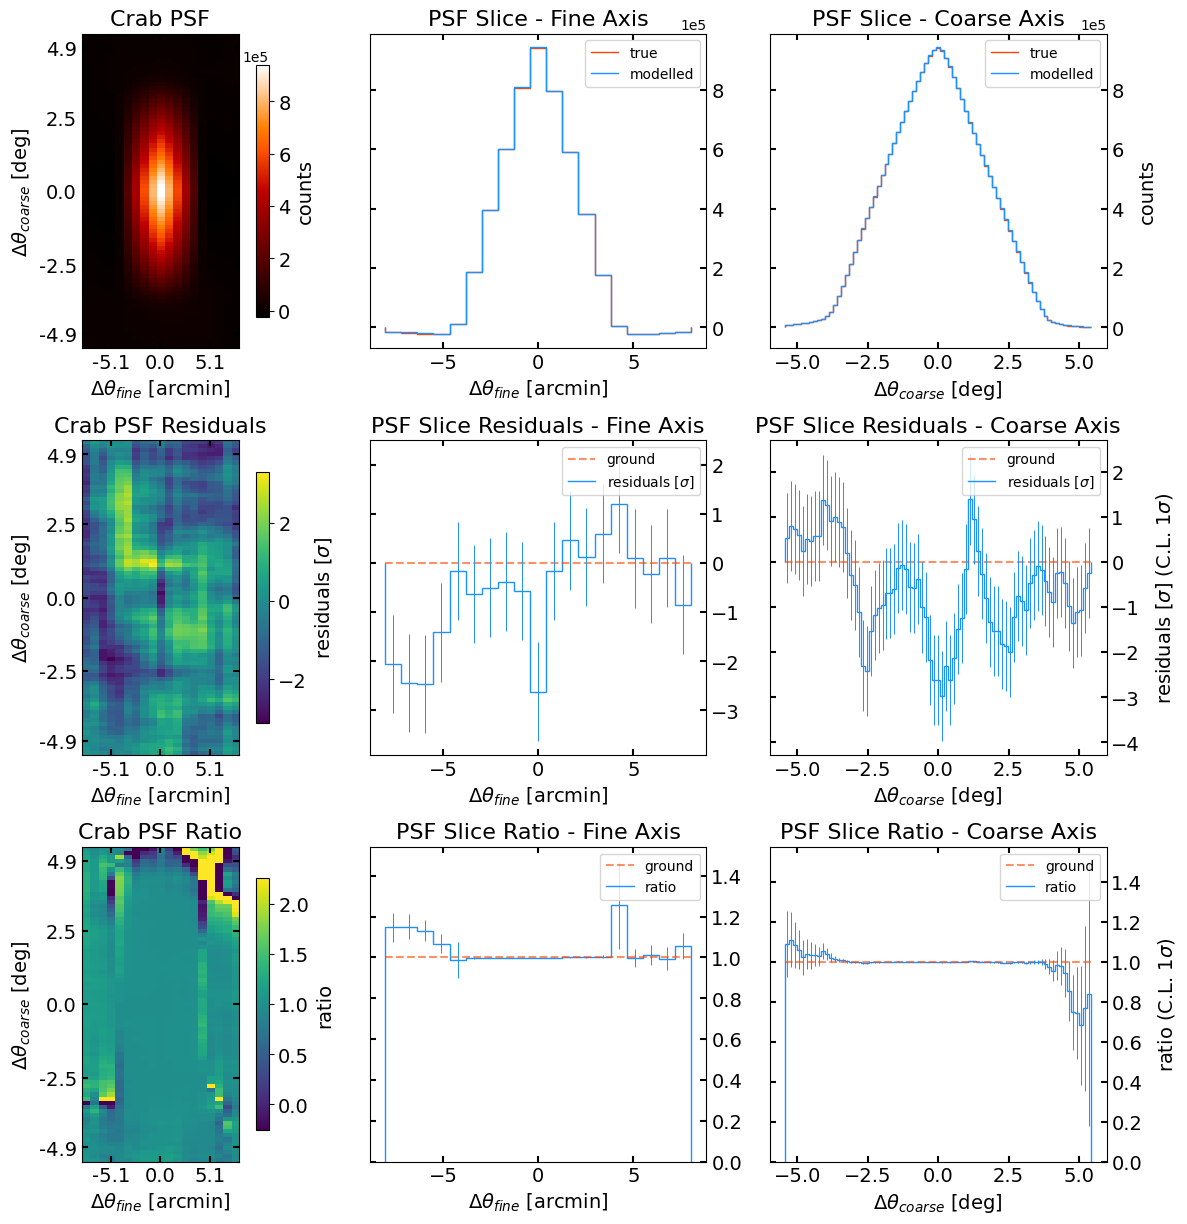

In [22]:
inspect_src(
    camera=wfm,
    log_cam=log_camA,
    skymap=skymapA,
    varmap=varmapA,
    express_res_perc=True,
    express_res_sigma=True,
    n_sigma=1,
    # save_to=f'{OUT_RESULTS_PATH}/CrabProfile/{ID_CAMERA}/Crab_wsigma_GRID_1ks_{E_min}-{E_max}keV_{ID_CAMERA}.pdf',
    figsize=(4 * 3 + 0.5, 4 * 3 + 0.5),
    # fine_ratio_lims=(-12.0, 12.0),
    # coarse_ratio_lims=(-12.0, 12.0),
)